In [1]:
#load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

train = pd.read_csv("data/processed/train.csv")
test  = pd.read_csv("data/processed/test.csv")

X_train, y_train = train["text"], train["label"]
X_test,  y_test  = test["text"],  test["label"]
print(train.shape, test.shape)

(3659, 4) (915, 4)


In [ ]:
#build and train both models
models = {
    "NB + Bag-of-Words": Pipeline([("vec", CountVectorizer()), ("nb", MultinomialNB())]),
    "NB + TF-IDF":       Pipeline([("vec", TfidfVectorizer()), ("nb", MultinomialNB())]),
}

results, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)         
    y_pred = model.predict(X_test)      
    preds[name] = y_pred

    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    results.append({"model": name, "accuracy": accuracy_score(y_test, y_pred),
                    "precision": p, "recall": r, "f1": f1})
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3))

results_df = pd.DataFrame(results).round(3)
results_df

=== NB + Bag-of-Words ===
              precision    recall  f1-score   support

    negative      0.801     0.669     0.729       320
    positive      0.836     0.911     0.872       595

    accuracy                          0.826       915
   macro avg      0.819     0.790     0.801       915
weighted avg      0.824     0.826     0.822       915

=== NB + TF-IDF ===
              precision    recall  f1-score   support

    negative      0.938     0.281     0.433       320
    positive      0.719     0.990     0.833       595

    accuracy                          0.742       915
   macro avg      0.828     0.636     0.633       915
weighted avg      0.796     0.742     0.693       915



,model,accuracy,precision,recall,f1
0,NB + Bag-of-Words,0.826,0.819,0.790,0.801
1,NB + TF-IDF,0.742,0.828,0.636,0.633


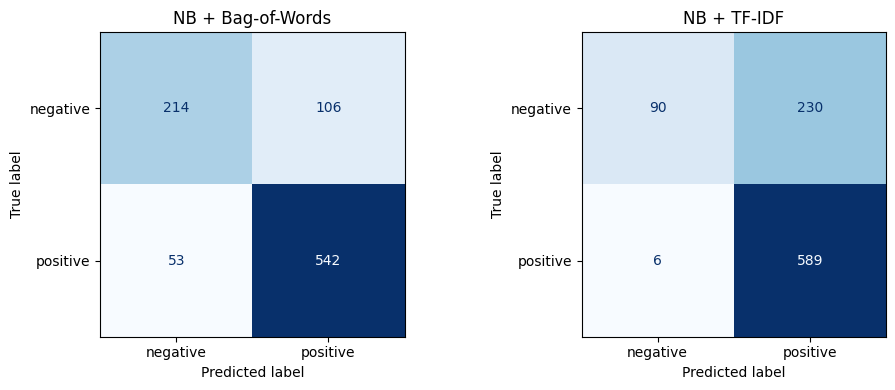

In [7]:
#confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [8]:
#which words the model learned
model = models["NB + Bag-of-Words"]
vec, nb = model.named_steps["vec"], model.named_steps["nb"]
words = np.array(vec.get_feature_names_out())
pos_i = list(nb.classes_).index("positive")
neg_i = list(nb.classes_).index("negative")
ratio = nb.feature_log_prob_[pos_i] - nb.feature_log_prob_[neg_i]

print("Most positive words:", ", ".join(words[np.argsort(ratio)[-15:][::-1]]))
print("Most negative words:", ", ".join(words[np.argsort(ratio)[:15]]))

Most positive words: pleased, amazing, love, happy, excellent, fits, beautiful, awesome, great, photo, outstanding, baby, results, allows, anywhere
Most negative words: unfortunately, poor, useless, flaw, press, repair, cannot, started, downside, busy, folders, sent, neither, recognize, worst


In [10]:
#look at mistakes, then save results
mistakes = test.assign(pred=preds["NB + TF-IDF"])
mistakes = mistakes[mistakes["label"] != mistakes["pred"]]
print(f"{len(mistakes)} wrong out of {len(test)}")
display(mistakes[["text", "label", "pred"]].head(10))

results_df.to_csv("results_02.csv", index=False)

236 wrong out of 915


,text,label,pred
0,i built my own router table with a tilt up top...,negative,positive
4,"since then, i have not found one major problem...",positive,negative
5,the linksys technical support site has nothing...,negative,positive
8,) button sensitivity: even reduced to the lowe...,negative,positive
17,who wants to pay $30 to discuss a defect in a ...,negative,positive
19,"on the downside, i think the interface takes s...",negative,positive
20,i guess i do n't have to mention that i do not...,negative,positive
24,i found that low light situations combined wit...,negative,positive
29,rather than creating a directory for bookmarks...,negative,positive
34,") creative, inc. the maker includes the barest...",negative,positive
